# Rubin alerts from Hugging Face with DuckDB
## An interpretable anomaly-detection baseline

This notebook downloads the Parquet files from the Hugging Face dataset `umbramortem/alerts_open_tools_open_sky_2026`, queries them with DuckDB without concatenating the full dataset in Pandas, constructs object-level features, ranks unusual objects with Isolation Forest, and inspects the leading candidates.

### Workflow

1. Download only Parquet files from Hugging Face.
2. Create a DuckDB view over all files.
3. Inspect the schema without loading the complete dataset into memory.
4. Detect likely Rubin identifier, time, band, flux, magnitude, and coordinate columns.
5. Aggregate alert measurements into one feature row per object using DuckDB.
6. Apply an Isolation Forest baseline in scikit-learn.
7. Retrieve and plot only the highest-ranked candidates.
8. Export the ranking and candidate rows.

> **Scientific caution:** a high anomaly score is a prioritization signal, not evidence of a new astrophysical phenomenon. Outliers can result from sparse sampling, image-subtraction artifacts, blending, low signal-to-noise measurements, or incorrect object associations.

## 0. Environment setup

For a local Conda environment, install the dependencies in a terminal before opening the notebook:

```bash
conda create -n rubin-anomaly -c conda-forge   python=3.11 numpy pandas pyarrow duckdb scikit-learn   matplotlib huggingface_hub jupyterlab ipykernel -y
conda activate rubin-anomaly
python -m ipykernel install --user --name rubin-anomaly   --display-name "Python (Rubin anomaly)"
```

Then select **Python (Rubin anomaly)** as the notebook kernel. Do not run a broad `pip install -U`, which can trigger unnecessary source builds on macOS.

For Colab only, uncomment and run the next line, then restart the runtime if requested.

In [ ]:
# Colab only:
# %pip install --only-binary=:all: duckdb huggingface_hub pyarrow scikit-learn

## 1. Imports and versions

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from huggingface_hub import HfApi, snapshot_download
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 150)
pd.set_option("display.max_colwidth", 120)

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("DuckDB:", duckdb.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

/Users/umbramortem/miniconda3/envs/rubin-anomaly/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.14
Python executable: /Users/umbramortem/miniconda3/envs/rubin-anomaly/bin/python
DuckDB: 1.4.4
Pandas: 3.0.0
NumPy: 2.4.2


## 2. Configuration

The repository is public, so a token is normally unnecessary. If a token is needed, save `HF_TOKEN` in Colab Secrets or export it as an environment variable.

In [2]:
REPO_ID = "umbramortem/alerts_open_tools_open_sky_2026"
REPO_TYPE = "dataset"
REVISION = "main"
RANDOM_STATE = 42
MIN_OBSERVATIONS = 2
TOP_N = 12

# Approximate quantiles are faster and adequate for a first anomaly ranking.
USE_APPROXIMATE_QUANTILES = True

# Adjust for your computer. DuckDB can spill intermediate data to disk.
DUCKDB_MEMORY_LIMIT = "8GB"
DUCKDB_TEMP_DIRECTORY = "duckdb_temp"
DUCKDB_THREADS = max(1, (os.cpu_count() or 2) - 1)

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

print("Repository:", REPO_ID)
print("DuckDB threads:", DUCKDB_THREADS)
print("DuckDB memory limit:", DUCKDB_MEMORY_LIMIT)

Repository: umbramortem/alerts_open_tools_open_sky_2026
DuckDB threads: 15
DuckDB memory limit: 8GB


## 3. Inspect the repository and download only Parquet files

The top-level JSON file is not used as the scientific table. The notebook explicitly selects the Parquet files stored below it.

In [3]:
api = HfApi(token=HF_TOKEN)
repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type=REPO_TYPE,
    revision=REVISION,
)

parquet_repo_files = sorted(
    name for name in repo_files
    if name.lower().endswith(".parquet")
)
json_repo_files = sorted(
    name for name in repo_files
    if name.lower().endswith((".json", ".jsonl"))
)

print(f"Repository files: {len(repo_files):,}")
print(f"Parquet files: {len(parquet_repo_files):,}")
print(f"JSON/JSONL files ignored as primary data: {len(json_repo_files):,}")

if not parquet_repo_files:
    raise FileNotFoundError("No Parquet files were found in the repository.")

print("\nParquet files:")
for name in parquet_repo_files:
    print(" -", name)

local_dataset_directory = Path(
    snapshot_download(
        repo_id=REPO_ID,
        repo_type=REPO_TYPE,
        revision=REVISION,
        token=HF_TOKEN,
        allow_patterns=["*.parquet", "**/*.parquet"],
    )
)

local_parquet_files = sorted(local_dataset_directory.rglob("*.parquet"))
if not local_parquet_files:
    raise FileNotFoundError("The snapshot was downloaded, but no local Parquet files were found.")

print("\nLocal snapshot:", local_dataset_directory)
print("Local Parquet files:", len(local_parquet_files))

Repository files: 6,369
Parquet files: 3,233
JSON/JSONL files ignored as primary data: 3,133

Parquet files:
 - XRUBIN_raw_all/detections/mjd-60973p13026719-60973p63026719.parquet
 - XRUBIN_raw_all/detections/mjd-60973p63026719-60974p13026719.parquet
 - XRUBIN_raw_all/detections/mjd-60974p13026719-60974p63026719.parquet
 - XRUBIN_raw_all/detections/mjd-60974p63026719-60975p13026719.parquet
 - XRUBIN_raw_all/detections/mjd-60975p13026719-60975p63026719.parquet
 - XRUBIN_raw_all/detections/mjd-60975p63026719-60976p13026719.parquet
 - XRUBIN_raw_all/detections/mjd-60976p13026719-60976p63026719.parquet
 - XRUBIN_raw_all/detections/mjd-60976p63026719-60977p13026719.parquet
 - XRUBIN_raw_all/detections/mjd-60977p13026719-60977p63026719.parquet
 - XRUBIN_raw_all/detections/mjd-60977p63026719-60978p13026719.parquet
 - XRUBIN_raw_all/detections/mjd-60978p13026719-60978p63026719.parquet
 - XRUBIN_raw_all/detections/mjd-60978p63026719-60979p13026719.parquet
 - XRUBIN_raw_all/detections/mjd-60979p

Fetching ... files: 3233it [00:01, 2426.72it/s]



Local snapshot: /Users/umbramortem/.cache/huggingface/hub/datasets--umbramortem--alerts_open_tools_open_sky_2026/snapshots/aa5281eceb31a2b9834d41a9489e6d307a9124a2
Local Parquet files: 3233


## 4. Create the DuckDB connection and Parquet view

DuckDB does not allow prepared parameters inside `CREATE VIEW` in some versions. Therefore, the file paths are escaped and inserted as SQL string literals.

In [4]:
connection = duckdb.connect(database=":memory:")
connection.execute(f"PRAGMA threads={DUCKDB_THREADS}")
connection.execute(f"PRAGMA memory_limit='{DUCKDB_MEMORY_LIMIT}'")
Path(DUCKDB_TEMP_DIRECTORY).mkdir(exist_ok=True)
connection.execute(f"PRAGMA temp_directory='{DUCKDB_TEMP_DIRECTORY}'")


def sql_string_literal(value):
    """Return a safely escaped SQL string literal."""
    return "'" + str(value).replace("'", "''") + "'"


parquet_paths = [str(path.resolve()) for path in local_parquet_files]
parquet_paths_sql = ",\n        ".join(
    sql_string_literal(path) for path in parquet_paths
)

create_view_query = f"""
CREATE OR REPLACE VIEW rubin_alerts AS
SELECT *
FROM read_parquet(
    [
        {parquet_paths_sql}
    ],
    union_by_name = true,
    filename = true
)
"""

connection.execute(create_view_query)
print("DuckDB view created over", len(parquet_paths), "Parquet files.")

DuckDB view created over 3233 Parquet files.


## 5. Inspect the dataset without loading it into Pandas

These queries return only the schema, a compact summary, and a small sample.

In [5]:
schema = connection.execute("DESCRIBE rubin_alerts").df()
display(schema)

dataset_summary = connection.execute("""
SELECT
    count(*) AS number_of_rows,
    count(DISTINCT filename) AS number_of_parquet_files
FROM rubin_alerts
""").df()
display(dataset_summary)

sample = connection.execute("SELECT * FROM rubin_alerts LIMIT 5").df()
display(sample)

,column_name,column_type,null,key,default,extra
0,oid,BIGINT,YES,None,None,None
1,measurement_id,BIGINT,YES,None,None,None
2,mjd,DOUBLE,YES,None,None,None
3,band_name,VARCHAR,YES,None,None,None
4,psfflux,FLOAT,YES,None,None,None
5,psffluxerr,FLOAT,YES,None,None,None
6,scienceflux,FLOAT,YES,None,None,None
7,sciencefluxerr,FLOAT,YES,None,None,None
8,templateflux,FLOAT,YES,None,None,None
9,templatefluxerr,FLOAT,YES,None,None,None


,number_of_rows,number_of_parquet_files
0,69653905,2215


,oid,measurement_id,mjd,band_name,psfflux,psffluxerr,scienceflux,sciencefluxerr,templateflux,templatefluxerr,isnegative,snr,reliability,isdipole,psfflux_flag,pixelflags_bad,pixelflags_cr,pixelflags_saturated,pixelflags_streak,glint_trail,validitystartmjdtai,firstdiasourcemjdtai,lastdiasourcemjdtai,ndiasources,u_psffluxndata,g_psffluxndata,r_psffluxndata,i_psffluxndata,z_psffluxndata,y_psffluxndata,filename
0,313629129589653560,313629129589653560,60973.169745,i,4451.933105,390.692352,42350.832031,411.757233,36908.015625,6.266848,False,9.690210,0.228454,False,False,False,False,False,False,False,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,/Users/umbramortem/.cache/huggingface/hub/datasets--umbramortem--alerts_open_tools_open_sky_2026/blobs/a8ef6528cc796...
1,313629129556623404,313629129556623404,60973.169745,i,2495.562500,379.948944,2769.399902,396.411713,-4.087404,6.799683,False,6.470420,0.632288,False,False,False,False,False,False,False,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,/Users/umbramortem/.cache/huggingface/hub/datasets--umbramortem--alerts_open_tools_open_sky_2026/blobs/a8ef6528cc796...
2,313629129583362067,313629129583362067,60973.169745,i,2516.010498,470.630493,162915.484375,497.498810,159577.921875,7.125452,False,5.086137,0.275779,False,False,False,False,False,False,False,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,/Users/umbramortem/.cache/huggingface/hub/datasets--umbramortem--alerts_open_tools_open_sky_2026/blobs/a8ef6528cc796...
3,313629129686646795,313629129686646795,60973.170251,i,2389.827393,440.143555,24212.988281,458.937073,21841.248047,13.754683,False,5.309637,0.306016,False,False,False,False,False,False,False,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,/Users/umbramortem/.cache/huggingface/hub/datasets--umbramortem--alerts_open_tools_open_sky_2026/blobs/a8ef6528cc796...
4,313629129721250087,313629129721250087,60973.170251,i,2030.461914,395.169617,1894.503296,407.750946,-163.104202,12.691509,False,5.056403,0.236224,False,False,False,False,False,False,False,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,/Users/umbramortem/.cache/huggingface/hub/datasets--umbramortem--alerts_open_tools_open_sky_2026/blobs/a8ef6528cc796...


## 6. Detect likely Rubin/light-curve columns

The automatic mapping is case-insensitive. Inspect it carefully. If any assignment is wrong, edit the manual override cell before continuing.

In [6]:
available_columns = schema["column_name"].astype(str).tolist()


def first_existing(candidates):
    lookup = {column.lower(): column for column in available_columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


COL = {
    "object_id": first_existing([
        "diaObjectId", "objectId", "object_id", "sourceId",
        "source_id", "alertId", "alert_id", "oid"
    ]),
    "time": first_existing([
        "midpointMjdTai", "mjd", "jd", "time", "timestamp"
    ]),
    "band": first_existing([
        "band", "filter", "filterName", "fid"
    ]),
    "flux": first_existing([
        "psfFlux", "differenceFlux", "diffFlux", "flux", "forcedDiffFlux"
    ]),
    "flux_err": first_existing([
        "psfFluxErr", "differenceFluxErr", "diffFluxErr",
        "flux_err", "fluxError", "forcedDiffFluxErr"
    ]),
    "mag": first_existing([
        "mag", "magnitude", "psfMag", "magpsf", "scienceMag"
    ]),
    "mag_err": first_existing([
        "magErr", "magnitude_error", "sigmapsf", "psfMagErr"
    ]),
    "ra": first_existing(["ra", "coord_ra", "ra_deg"]),
    "dec": first_existing(["dec", "decl", "coord_dec", "dec_deg"]),
}

print(json.dumps(COL, indent=2))

{
  "object_id": "oid",
  "time": "mjd",
  "band": null,
  "flux": "psfflux",
  "flux_err": "psffluxerr",
  "mag": null,
  "mag_err": null,
  "ra": null,
  "dec": null
}


### Manual overrides

Uncomment and modify entries only if the automatic mapping is incorrect.

In [7]:
# Examples:
# COL["object_id"] = "diaObjectId"
# COL["time"] = "midpointMjdTai"
# COL["band"] = "band"
# COL["flux"] = "psfFlux"
# COL["flux_err"] = "psfFluxErr"
# COL["mag"] = None
# COL["mag_err"] = None

if COL["object_id"] is None:
    raise KeyError("No object identifier was detected. Set COL['object_id'] manually.")
if COL["flux"] is None and COL["mag"] is None:
    raise KeyError("No flux or magnitude column was detected. Set COL['flux'] or COL['mag'] manually.")

print("Column mapping accepted:")
print(json.dumps(COL, indent=2))

Column mapping accepted:
{
  "object_id": "oid",
  "time": "mjd",
  "band": null,
  "flux": "psfflux",
  "flux_err": "psffluxerr",
  "mag": null,
  "mag_err": null,
  "ra": null,
  "dec": null
}


## 7. Build object-level features in DuckDB

This is the optimized replacement for the slow Pandas `groupby.apply()` cell. DuckDB reads only required columns and performs vectorized aggregation over all Parquet files. Approximate quantiles can be used for the first ranking.

In [8]:
def quote_identifier(name):
    if name is None:
        return None

    return '"' + str(name).replace('"', '""') + '"'


q = {
    key: quote_identifier(value)
    for key, value in COL.items()
}

measurement_key = (
    "flux"
    if COL["flux"] is not None
    else "mag"
)

measurement_sql = q[measurement_key]
object_id_sql = q["object_id"]

print("Measurement:", measurement_key)
print("Object identifier:", COL["object_id"])

Measurement: flux
Object identifier: oid


In [9]:
prepared_columns = [
    f"CAST({object_id_sql} AS VARCHAR) AS object_id",
    f"TRY_CAST({measurement_sql} AS DOUBLE) AS measurement",
]

if q["time"] is not None:
    prepared_columns.append(
        f"TRY_CAST({q['time']} AS DOUBLE) AS observation_time"
    )

if q["band"] is not None:
    prepared_columns.append(
        f"{q['band']} AS band"
    )

if q["flux"] is not None and q["flux_err"] is not None:
    prepared_columns.extend(
        [
            f"TRY_CAST({q['flux']} AS DOUBLE) AS flux",
            f"TRY_CAST({q['flux_err']} AS DOUBLE) AS flux_error",
        ]
    )

if q["ra"] is not None:
    prepared_columns.append(
        f"TRY_CAST({q['ra']} AS DOUBLE) AS ra"
    )

if q["dec"] is not None:
    prepared_columns.append(
        f"TRY_CAST({q['dec']} AS DOUBLE) AS dec"
    )

In [11]:
fast_expressions = [
    "object_id",
    "count(*) AS n_observations",
    "avg(measurement) AS measurement_mean",
    "stddev_samp(measurement) AS measurement_std",
    "min(measurement) AS measurement_min",
    "max(measurement) AS measurement_max",
    (
        "max(measurement) - min(measurement) "
        "AS measurement_range"
    ),
]

In [12]:
if q["time"] is not None:
    fast_expressions.extend(
        [
            "min(observation_time) AS time_min",
            "max(observation_time) AS time_max",
            (
                "max(observation_time) "
                "- min(observation_time) "
                "AS time_baseline"
            ),
        ]
    )

In [13]:
INCLUDE_BAND_COUNT = False

if q["band"] is not None and INCLUDE_BAND_COUNT:
    fast_expressions.append(
        "count(DISTINCT band) AS n_bands"
    )

## 8. Review feature completeness

Columns that are entirely missing are removed before modeling. Highly incomplete columns are displayed for scientific review.

In [16]:
from time import perf_counter

connection.execute(
    "SET preserve_insertion_order = false"
)

# Start conservatively on the local computer.
connection.execute(
    "SET threads = 4"
)


def quote_identifier(name):
    if name is None:
        return None

    return '"' + str(name).replace('"', '""') + '"'


q = {
    key: quote_identifier(value)
    for key, value in COL.items()
}


measurement_key = (
    "flux"
    if COL["flux"] is not None
    else "mag"
)

measurement_sql = q[measurement_key]
object_id_sql = q["object_id"]


prepared_columns = [
    (
        f"CAST({object_id_sql} AS VARCHAR) "
        f"AS object_id"
    ),
    (
        f"TRY_CAST({measurement_sql} AS DOUBLE) "
        f"AS measurement"
    ),
]


if q["time"] is not None:
    prepared_columns.append(
        f"""
        TRY_CAST(
            {q["time"]}
            AS DOUBLE
        ) AS observation_time
        """
    )


if q["band"] is not None:
    prepared_columns.append(
        f"{q['band']} AS band"
    )


if (
    q["flux"] is not None
    and q["flux_err"] is not None
):
    prepared_columns.extend(
        [
            (
                f"TRY_CAST({q['flux']} AS DOUBLE) "
                f"AS flux"
            ),
            (
                f"TRY_CAST({q['flux_err']} AS DOUBLE) "
                f"AS flux_error"
            ),
        ]
    )


if q["ra"] is not None:
    prepared_columns.append(
        f"""
        TRY_CAST(
            {q["ra"]}
            AS DOUBLE
        ) AS ra
        """
    )


if q["dec"] is not None:
    prepared_columns.append(
        f"""
        TRY_CAST(
            {q["dec"]}
            AS DOUBLE
        ) AS dec
        """
    )


fast_expressions = [
    "object_id",
    "count(*) AS n_observations",
    "avg(measurement) AS measurement_mean",
    "stddev_samp(measurement) AS measurement_std",
    "min(measurement) AS measurement_min",
    "max(measurement) AS measurement_max",
    (
        "max(measurement) "
        "- min(measurement) "
        "AS measurement_range"
    ),
]


if q["time"] is not None:
    fast_expressions.extend(
        [
            "min(observation_time) AS time_min",
            "max(observation_time) AS time_max",
            (
                "max(observation_time) "
                "- min(observation_time) "
                "AS time_baseline"
            ),
        ]
    )


# Keep this off for the fastest first analysis.
INCLUDE_BAND_COUNT = False

if (
    q["band"] is not None
    and INCLUDE_BAND_COUNT
):
    fast_expressions.append(
        "count(DISTINCT band) AS n_bands"
    )


if (
    q["flux"] is not None
    and q["flux_err"] is not None
):
    fast_expressions.extend(
        [
            """
            avg(
                flux / NULLIF(flux_error, 0)
            ) AS snr_mean
            """,
            """
            max(
                abs(
                    flux / NULLIF(flux_error, 0)
                )
            ) AS snr_max_abs
            """,
        ]
    )


if q["ra"] is not None:
    fast_expressions.append(
        "avg(ra) AS ra_mean"
    )


if q["dec"] is not None:
    fast_expressions.append(
        "avg(dec) AS dec_mean"
    )


fast_feature_query = f"""
WITH prepared AS (
    SELECT
        {", ".join(prepared_columns)}
    FROM rubin_alerts
    WHERE {object_id_sql} IS NOT NULL
)

SELECT
    {", ".join(fast_expressions)}

FROM prepared

WHERE measurement IS NOT NULL

GROUP BY object_id

HAVING count(*) >= {int(MIN_OBSERVATIONS)}
"""


print("Running fast object-level aggregation...")

start = perf_counter()


features = (
    connection
    .execute(fast_feature_query)
    .df()
    .set_index("object_id")
)


features = features.replace(
    [np.inf, -np.inf],
    np.nan,
)


elapsed = perf_counter() - start


print(
    f"Feature extraction completed in "
    f"{elapsed:.1f} seconds."
)

print(
    "Object-level feature matrix:",
    features.shape,
)

display(features.head())

Running fast object-level aggregation...
Feature extraction completed in 16.2 seconds.
Object-level feature matrix: (1611647, 11)


,n_observations,measurement_mean,measurement_std,measurement_min,measurement_max,measurement_range,time_min,time_max,time_baseline,snr_mean,snr_max_abs
object_id,,,,,,,,,,,
313673106977718296,8,5406.810059,4888.680809,-3484.613281,14212.420898,17697.034180,60983.202287,61060.080260,76.877973,10.647969,21.367161
313690717367042052,298,-3982.299066,10603.792596,-162327.765625,12615.800781,174943.566406,60987.280459,61100.078414,112.797954,-9.474536,559.735778
313690717021536289,7,2994.974226,901.614620,2285.370850,4926.434570,2641.063721,60987.278792,61049.091287,61.812495,9.103231,11.576498
313708285388652631,2,-827.584106,243.143397,-999.512451,-655.655762,343.856689,60991.237160,61051.066036,59.828876,-5.437496,5.521135
313708285512908834,3,4100.840780,3054.410926,1200.536499,7288.980957,6088.444458,60991.237618,61049.096055,57.858437,8.777500,14.770463


In [17]:
feature_quality = pd.DataFrame({
    "dtype": features.dtypes.astype(str),
    "missing_fraction": features.isna().mean(),
    "n_unique": features.nunique(dropna=True),
}).sort_values("missing_fraction", ascending=False)

display(feature_quality)

all_missing = feature_quality.index[feature_quality["missing_fraction"] == 1.0].tolist()
if all_missing:
    print("Dropping entirely missing columns:", all_missing)
    features = features.drop(columns=all_missing)

,dtype,missing_fraction,n_unique
n_observations,int64,0.0,2073
measurement_mean,float64,0.0,1609612
measurement_std,float64,0.0,1600107
measurement_min,float64,0.0,1593309
measurement_max,float64,0.0,1590319
measurement_range,float64,0.0,1568165
time_min,float64,0.0,5223
time_max,float64,0.0,5418
time_baseline,float64,0.0,165451
snr_mean,float64,0.0,1611647


## 9. Isolation Forest baseline

Coordinate columns are retained for interpretation but excluded from the default anomaly model. The score is negated so that larger values indicate more unusual objects.

In [18]:
excluded_from_model = {"ra_median", "dec_median", "time_min", "time_max"}
model_columns = [
    column for column in features.columns
    if column not in excluded_from_model
    and pd.api.types.is_numeric_dtype(features[column])
    and features[column].nunique(dropna=True) > 1
]

if len(features) < 10:
    raise ValueError(f"Only {len(features)} eligible objects were found; a larger sample is needed.")
if not model_columns:
    raise ValueError("No usable numerical model features were found.")

print("Model columns:")
for column in model_columns:
    print(" -", column)

X = features[model_columns]
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("isolation_forest", IsolationForest(
        n_estimators=300,
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

model.fit(X)
ranked = features.copy()
ranked["anomaly_score"] = -model.decision_function(X)
ranked = ranked.sort_values("anomaly_score", ascending=False)
ranked["anomaly_rank"] = np.arange(1, len(ranked) + 1)

display(ranked.head(20))

Model columns:
 - n_observations
 - measurement_mean
 - measurement_std
 - measurement_min
 - measurement_max
 - measurement_range
 - time_baseline
 - snr_mean
 - snr_max_abs


,n_observations,measurement_mean,measurement_std,measurement_min,measurement_max,measurement_range,time_min,time_max,time_baseline,snr_mean,snr_max_abs,anomaly_score,anomaly_rank
object_id,,,,,,,,,,,,,
170028488495988786,365,-9.095671e+05,1.201568e+06,-4609742.50,8.035915e+05,5.413334e+06,61090.062357,61219.423609,129.361252,-434.566644,4670.105841,0.347820,1
170028489306538072,394,-1.129681e+06,1.308995e+06,-3289574.50,1.030948e+06,4.320523e+06,61090.064952,61219.424102,129.359151,-596.143507,5115.141912,0.347629,2
170028489282420754,551,-3.956005e+05,7.094533e+05,-2924083.25,7.094037e+05,3.633487e+06,61090.064952,61219.420267,129.355316,-385.647915,6791.779100,0.347438,3
170028489720201220,559,-4.135095e+05,6.600765e+05,-2980642.00,7.301224e+05,3.710764e+06,61090.066470,61235.413181,145.346711,-393.593350,6076.716013,0.347246,4
313831458605105176,536,-2.547092e+05,6.273171e+05,-2152047.00,9.284100e+05,3.080457e+06,61019.291626,61235.418246,216.126620,-268.086984,4854.475372,0.347055,5
170028489829777462,334,-4.807778e+05,7.902965e+05,-3380420.00,7.861279e+05,4.166548e+06,61090.066905,61219.424102,129.357197,-437.047550,10026.491909,0.346864,6
170028489861234773,452,-1.071159e+06,9.434531e+05,-3326324.50,1.205822e+06,4.532146e+06,61090.066905,61235.413181,145.346276,-842.777004,7661.594590,0.346864,7
170028489479028747,402,-6.292924e+05,8.862260e+05,-3052828.75,6.819088e+05,3.734738e+06,61090.065383,61219.424588,129.359204,-514.611044,6147.259559,0.346673,8
170028489988636680,577,-8.609835e+05,1.137398e+06,-3539135.75,8.320936e+05,4.371229e+06,61090.067336,61217.422705,127.355369,-549.873504,3710.958202,0.346673,9


## 10. Score distribution

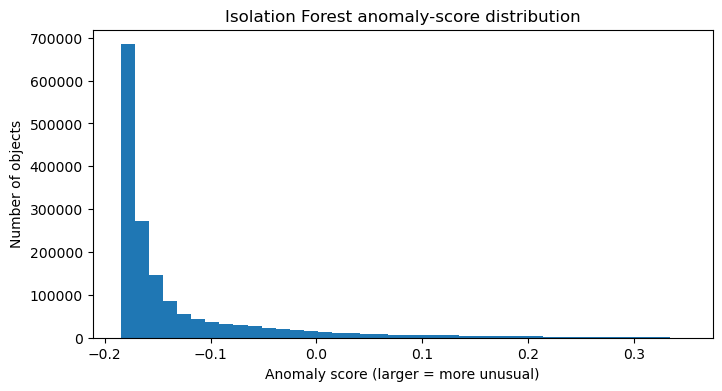

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ranked["anomaly_score"], bins=40)
ax.set_xlabel("Anomaly score (larger = more unusual)")
ax.set_ylabel("Number of objects")
ax.set_title("Isolation Forest anomaly-score distribution")
plt.show()

## 11. Retrieve and plot only the leading candidates

The full alert table remains in DuckDB. Pandas receives only the rows belonging to the selected object.

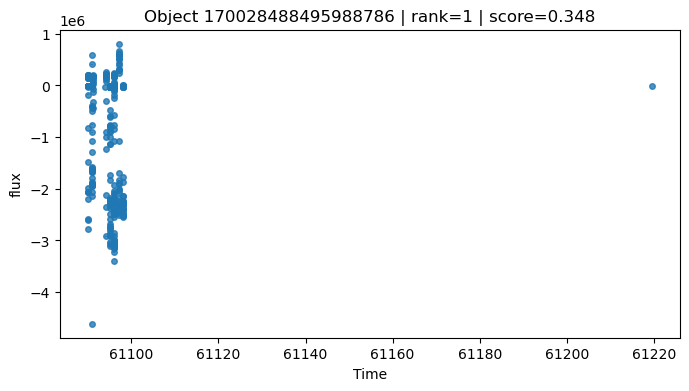

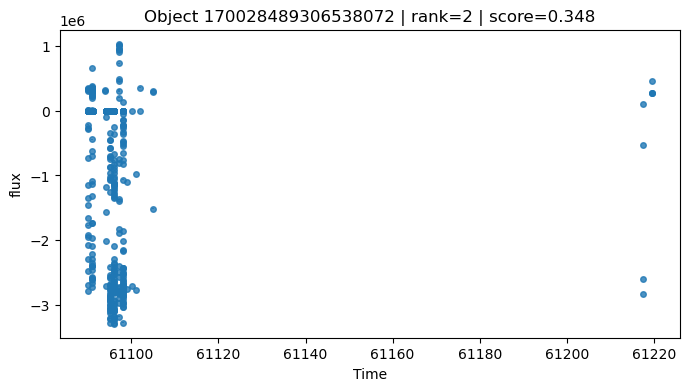

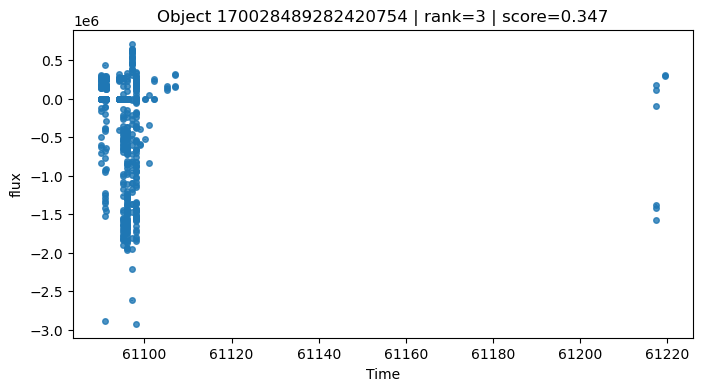

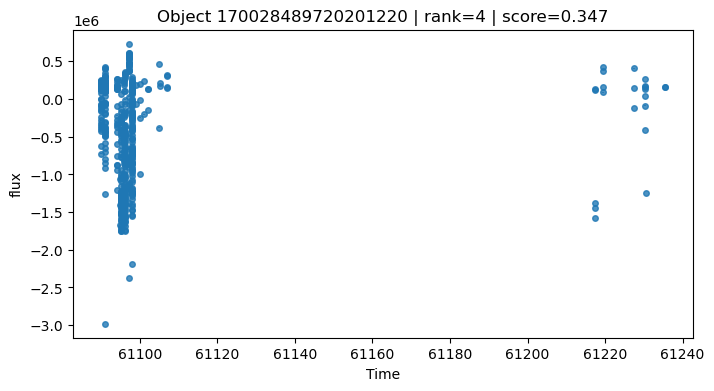

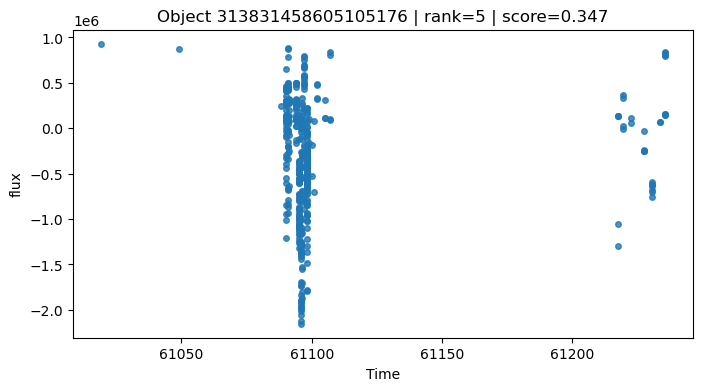

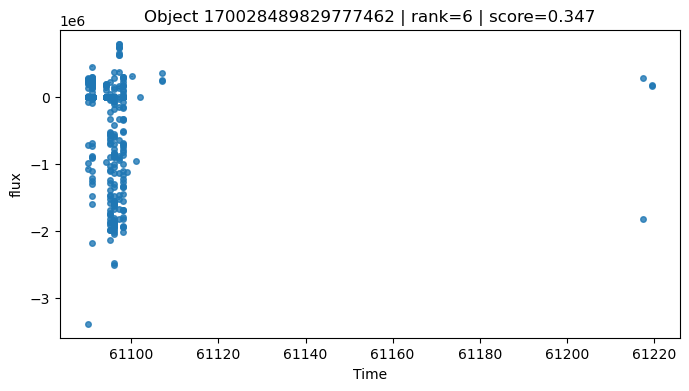

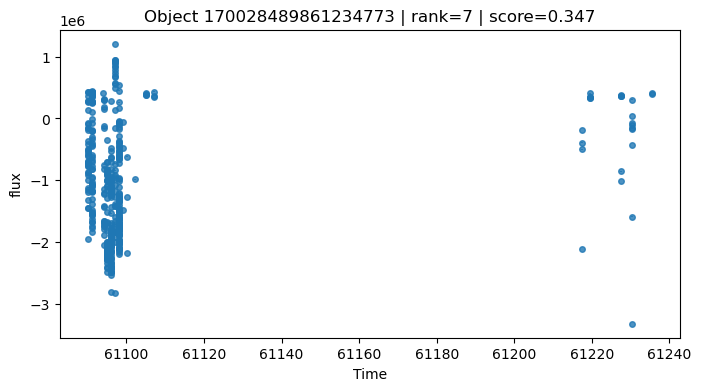

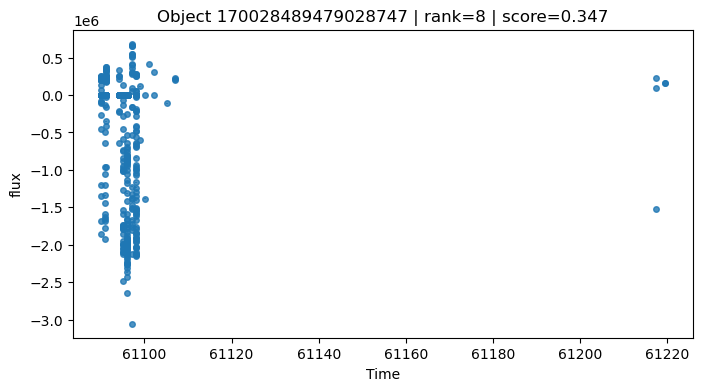

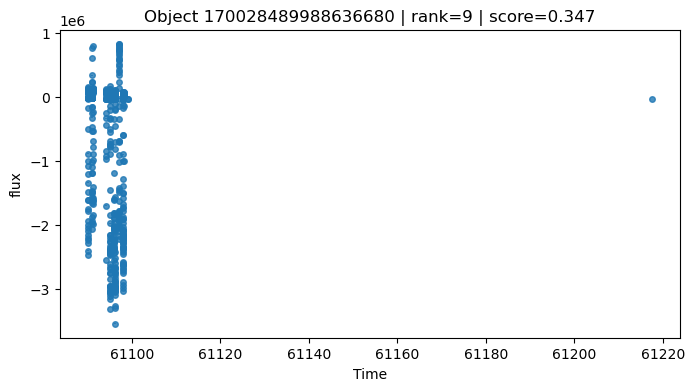

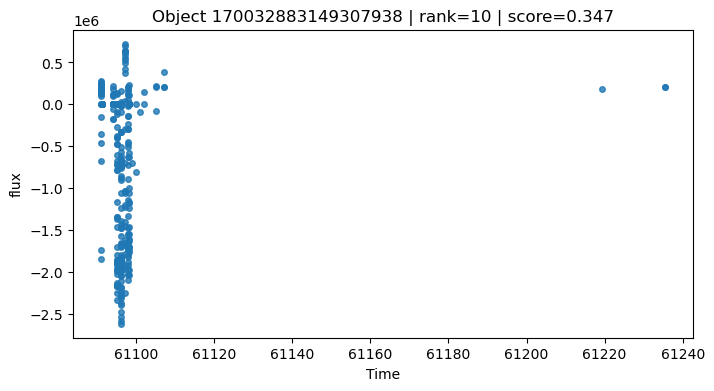

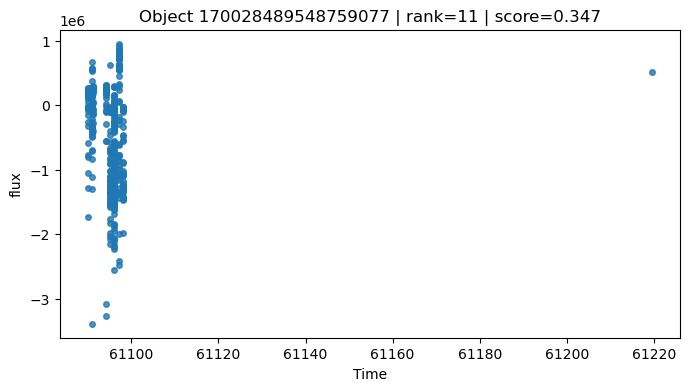

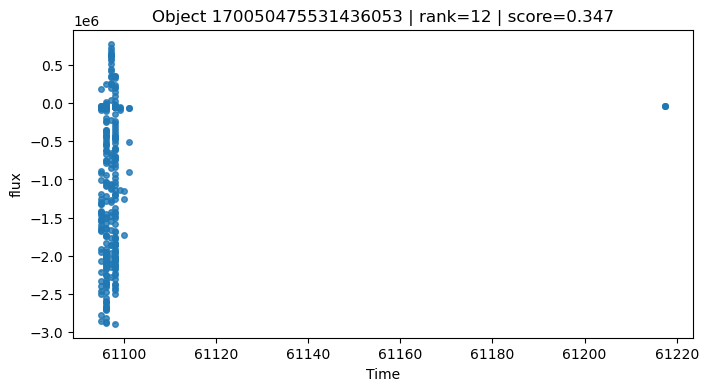

In [20]:
def get_object_observations(object_id):
    # Parameters are allowed in SELECT statements.
    order_clause = ""
    if q["time"] is not None:
        order_clause = f"ORDER BY TRY_CAST({q['time']} AS DOUBLE)"

    query = f"""
    SELECT *
    FROM rubin_alerts
    WHERE CAST({q['object_id']} AS VARCHAR) = ?
    {order_clause}
    """
    return connection.execute(query, [str(object_id)]).df()


def standardize_candidate(raw):
    candidate = pd.DataFrame(index=raw.index)
    for standard_name, original_name in COL.items():
        if original_name is not None and original_name in raw.columns:
            candidate[standard_name] = raw[original_name]

    candidate["object_id"] = candidate["object_id"].astype(str)
    for column in ["time", "flux", "flux_err", "mag", "mag_err", "ra", "dec"]:
        if column in candidate:
            candidate[column] = pd.to_numeric(candidate[column], errors="coerce")
    return candidate


def plot_candidate(object_id):
    raw = get_object_observations(object_id)
    candidate = standardize_candidate(raw)

    if "time" in candidate:
        candidate = candidate.sort_values("time")
        x_label = "Time"
    else:
        x_label = "Observation index"

    y_column = "mag" if "mag" in candidate else "flux"
    error_column = None
    if y_column == "mag" and "mag_err" in candidate:
        error_column = "mag_err"
    elif y_column == "flux" and "flux_err" in candidate:
        error_column = "flux_err"

    fig, ax = plt.subplots(figsize=(8, 4))
    groups = candidate.groupby("band", dropna=False) if "band" in candidate else [("all", candidate)]

    for band, part in groups:
        x = part["time"] if "time" in part else np.arange(len(part))
        if error_column is not None:
            ax.errorbar(x, part[y_column], yerr=part[error_column], fmt="o", ms=4, alpha=0.8, label=str(band))
        else:
            ax.scatter(x, part[y_column], s=24, alpha=0.8, label=str(band))

    if "band" in candidate:
        ax.legend(title="Band", ncol=3, fontsize=8)
    if y_column == "mag":
        ax.invert_yaxis()

    score = ranked.loc[str(object_id), "anomaly_score"]
    rank = ranked.loc[str(object_id), "anomaly_rank"]
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_column)
    ax.set_title(f"Object {object_id} | rank={rank} | score={score:.3f}")
    plt.show()


top_ids = ranked.head(TOP_N).index.astype(str).tolist()
for object_id in top_ids:
    plot_candidate(object_id)

## 12. Optional two-dimensional view of feature space

PCA is used only for visualization. It is not part of the anomaly detector.

In [ ]:
from sklearn.decomposition import PCA

prepared_X = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
]).fit_transform(X)

coordinates = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(prepared_X)
pca_frame = pd.DataFrame(coordinates, index=ranked.index if False else features.index, columns=["PC1", "PC2"])
pca_frame["anomaly_score"] = ranked["anomaly_score"].reindex(pca_frame.index)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    pca_frame["PC1"], pca_frame["PC2"],
    c=pca_frame["anomaly_score"], s=12, alpha=0.7,
)
ax.scatter(
    pca_frame.loc[top_ids, "PC1"], pca_frame.loc[top_ids, "PC2"],
    facecolors="none", edgecolors="red", s=70, linewidths=1.2,
    label=f"Top {TOP_N}",
)
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("Object-level feature space")
ax.legend()
fig.colorbar(scatter, ax=ax, label="Anomaly score")
plt.show()

## 13. Export rankings and original candidate rows

In [ ]:
ranking_file = "rubin_anomaly_ranking.csv"
candidate_file = "rubin_top_candidate_rows.parquet"

ranked.reset_index().to_csv(ranking_file, index=False)

placeholders = ", ".join(["?"] * len(top_ids))
candidate_query = f"""
SELECT *
FROM rubin_alerts
WHERE CAST({q['object_id']} AS VARCHAR) IN ({placeholders})
"""
top_candidate_rows = connection.execute(candidate_query, top_ids).df()
top_candidate_rows.to_parquet(candidate_file, index=False)

print("Saved:")
print(" -", ranking_file)
print(" -", candidate_file)
print("Candidate rows:", len(top_candidate_rows))

## 14. Scientific vetting checklist

For each high-ranked source, assign a preliminary interpretation:

- plausible astrophysical anomaly;
- known but rare source type;
- insufficient or uneven sampling;
- low signal-to-noise measurements;
- image-subtraction artifact;
- blending or crowded-field issue;
- association or crossmatch problem;
- requires additional contextual information.

### Recommended next steps

1. Confirm the exact meaning and units of the selected Rubin columns.
2. Incorporate alert quality flags before interpreting extreme measurements.
3. Separate detection-level anomalies from object-level temporal anomalies.
4. Calculate selected statistics per band in addition to global statistics.
5. Crossmatch candidates with Gaia, VSX, SIMBAD, or another relevant catalog.
6. Create a small human-vetted candidate set for evaluating future methods.
7. Compare this interpretable baseline with Local Outlier Factor, clustering, or learned time-series representations.